# 00 · Reading a scroll nobody can open

> **New to this?** Every term is explained in plain words in the [glossary](glossary.ipynb).

**The problem.** In 79 AD Vesuvius buried a villa at Herculaneum under some twenty metres of volcanic material. The
villa held a library. Its papyrus scrolls were carbonised: they survived as black lumps that crumble if you try to
unroll them. Roughly a thousand are still unread. The Vesuvius Challenge reads them **without opening them**: scan the
scroll with X-rays, find the papyrus sheet inside the 3D scan, flatten it, and detect the ink.

**Why this is hard, in one table.**

| step | what goes wrong |
|---|---|
| scanning | ink and papyrus are both carbon, so they absorb X-rays almost equally |
| finding the sheet | wraps are crushed together, torn, and stuck to each other |
| following one sheet | a tracer that jumps to the neighbouring wrap reads text from the wrong page |
| flattening | the sheet is stretched and folded, so a flat image distorts the letters |
| ink detection | the ink shows only as a faint surface texture, and a model trained on one scroll often fails on the next |

**This notebook** covers the history, how the scans are made, the full pipeline and the data, then streams a real
scroll (PHerc. 139) from the public S3 bucket and measures it. Nothing is downloaded in bulk.

| notebook | step of the pipeline | open problem it touches (see section 6) |
|---|---|---|
| 00 | the problem, the scan, the data | 10 data infrastructure |
| 01 | the volume: pyramids, chunks, air vs papyrus, sheet normals | 2 surface prediction |
| 02 | flattening: render a sheet from its mesh, measure its distortion | 3 mesh tracing |
| 03 | ink detection: a small 2.5D CNN on pseudo-labels | 7 ink generalisation |
| 04 | few labels: does self-supervised pretraining help? | 9 self-supervised representations |
| 05 | uncrushing a cross-section with flows | 6 spiral fit and global priors |

In [1]:
# On Google Colab: fetch the code and the two missing libraries. Locally this cell does nothing.
import sys, os
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/vesuvius-labs'):
        !git clone -q https://github.com/alexchilton/vesuvius-labs /content/vesuvius-labs
        !pip -q install "zarr<3" s3fs tifffile
    os.chdir('/content/vesuvius-labs/notebooks')

In [2]:
import sys, time, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
import vlab
plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'gray'})

## 1. How we got here

| when | what happened |
|---|---|
| 79 AD | Vesuvius erupts; the Villa of the Papyri and its library are buried |
| 18th century | the villa is excavated and the scrolls are found; attempts to unroll them by hand and by machine destroy many and expose only scraps |
| 2015 | Brent Seales' team (University of Kentucky) virtually unwraps the En-Gedi scroll and reads Leviticus. Its ink contained metal, so it was visible in X-ray; Herculaneum ink is not |
| March 2023 | the Vesuvius Challenge launches with public synchrotron scans and a prize fund |
| August 2023 | Casey Handmer spots the **crackle pattern**: a faint cracked texture where ink sits on the papyrus. First convincing evidence of ink inside a closed scroll ($10,000) |
| October 2023 | Luke Farritor trains a model on crackle and reads the first word from inside a scroll: ΠΟΡΦΥΡΑϹ, "purple" |
| 5 February 2024 | 2023 Grand Prize ($700,000) to Youssef Nader, Luke Farritor and Julian Schilliger: 15 columns, more than 2,000 characters, about 5% of PHerc. Paris. 4. The text is about pleasure, likely by the Epicurean Philodemus |
| December 2024 | first automated segmentation prize ($60,000): the 2023 result reproduced with far less manual tracing |
| May 2025 | first title of a sealed scroll read ($60,000, Marcel Roth and Micha Nowak) |
| March 2026 | Kaggle Surface Detection competition ($200,000): topologically correct papyrus detection |
| October 2026 | First Letters prize for PHerc. 343 ($50,000, Erwin Nieuwlaar): "πᾶν τὸ γινόμε[νον", "everything that happens" |
| 2027 | the Grand Prize ($1,000,000) asks for a **fully** unrolled scroll, with at most 8 hours of human annotation |

Total awarded since 2023: $1,958,500 (scrollprize.org/winners, October 2026). The shift over these years is the
lesson: 2023 was won with careful *human* tracing plus ML ink detection on 5% of one scroll; the open question now is
**automation at scale**.

## 2. How a scroll is scanned

```
   X-ray source ═══════► rotating scroll ═══════► detector
   (synchrotron beam)    (hundreds to thousands    (one 2D projection
                          of angles)                per angle)
                                     │
                         tomographic reconstruction
                                     ▼
                  a 3D grid of voxels: z = along the scroll axis
```

The scrolls were scanned at particle accelerators (Diamond Light Source in the UK, ESRF in France), not hospital CT.
A synchrotron beam is bright and coherent enough for **phase-contrast** imaging: besides absorption it records how the
beam is bent at edges, which makes thin structures such as the ink layer stand out. The price of resolution is data
size, which grows with the cube of the voxel count:

In [3]:
level0_gb, base_um = 20974 * 6621 * 6621 / 1e9, 9.362            # PHerc. 139 at 9.362 µm, measured in section 4
for um in (9.362, 4.0, 2.4, 1.1):
    print(f'{um:6.3f} µm voxels: {level0_gb * (base_um / um) ** 3 / 1e3:9.1f} TB for the whole scroll as uint8')

 9.362 µm voxels:       0.9 TB for the whole scroll as uint8
 4.000 µm voxels:      11.8 TB for the whole scroll as uint8
 2.400 µm voxels:      54.6 TB for the whole scroll as uint8
 1.100 µm voxels:     566.8 TB for the whole scroll as uint8


A 2.4 µm scan of one scroll is tens of terabytes. This is why the challenge stores scans as **pyramids of chunks**
(section 4, notebook 01) and why most work happens on small crops.

## 3. The pipeline

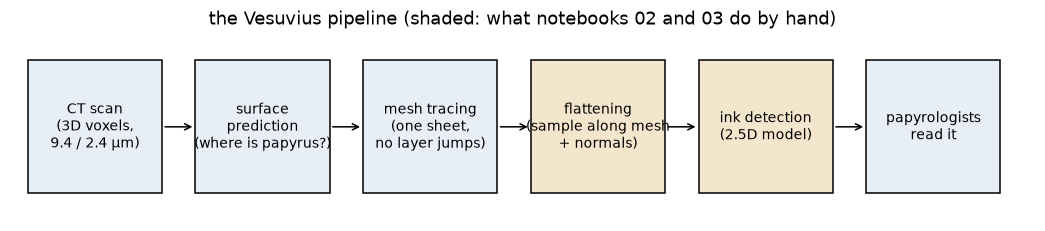

In [4]:
fig, ax = plt.subplots(figsize=(12, 2.2)); ax.axis('off')
steps = ['CT scan\n(3D voxels,\n9.4 / 2.4 µm)', 'surface\nprediction\n(where is papyrus?)', 'mesh tracing\n(one sheet,\nno layer jumps)',
         'flattening\n(sample along mesh\n+ normals)', 'ink detection\n(2.5D model)', 'papyrologists\nread it']
for i, s in enumerate(steps):
    ax.add_patch(plt.Rectangle((i * 2, 0), 1.6, 1, fc='#f3e6cc' if i in (3, 4) else '#e8eef6', ec='k'))
    ax.text(i * 2 + .8, .5, s, ha='center', va='center', fontsize=9)
    if i < len(steps) - 1: ax.annotate('', (i * 2 + 2, .5), (i * 2 + 1.6, .5), arrowprops=dict(arrowstyle='->'))
ax.set_xlim(-.2, 12); ax.set_ylim(-.2, 1.2); ax.set_title('the Vesuvius pipeline (shaded: what notebooks 02 and 03 do by hand)'); plt.show()

| stage | input → output | how it is done today | why it is hard |
|---|---|---|---|
| surface prediction | volume → "is this voxel papyrus surface?" | 3D segmentation networks (nnU-Net ensembles) | touching wraps merge; holes; the label itself is approximate |
| mesh tracing | surface prediction → one continuous sheet as a mesh | semi-automatic tracers in Volume Cartographer (VC3D), patch growing, human correction | one wrong step jumps to the next wrap; errors compound over thousands of slices |
| flattening | mesh → a flat parametrisation | minimise stretch (like flattening an orange peel) | a crumpled sheet cannot be flattened without distortion |
| rendering | mesh + volume → **surface volume**: ~28–65 layers sampled along the normals | trilinear sampling (we do it by hand in 02) | the mesh is only roughly on the sheet, so a slab of layers is sampled |
| ink detection | surface volume → 2D ink map | 2.5D or 3D CNNs trained on few, noisy labels | ink is a faint texture; models trained on one scroll fail on another |

## 4. The data

The scans live in `s3://vesuvius-challenge-open-data/` (anonymous read, CC-BY-NC 4.0), one folder per scroll or
fragment. Each scan is an **OME-Zarr** pyramid: level 0 is full resolution, every further level halves each axis.
The array axes are `(z, y, x)`; `z` runs along the scroll's long axis.

In [5]:
top = sorted(p.split('/')[-1] for p in vlab.FS.ls(vlab.BUCKET))
print(len(top), 'top-level folders, e.g.', top[:8])
s = vlab.SCROLL
print(f'{s}:', [p.split('/')[-1] for p in vlab.FS.ls(f'{vlab.BUCKET}/{s}')])
segs = vlab.FS.ls(f'{vlab.BUCKET}/{s}/segments')
print(f'{s} has {len(segs)} traced segments, e.g.', [p.split('/')[-1] for p in segs[:3]])
for lvl in range(6):
    a = vlab.scroll_volume(lvl)
    print(f"level {lvl}: shape {a.shape}, {np.prod(a.shape) / 1e9:8.2f} GB as uint8, chunks {a.chunks}")

51 top-level folders, e.g. ['LICENSE.txt', 'PHerc0009B', 'PHerc0125', 'PHerc0139', 'PHerc0172', 'PHerc0175A', 'PHerc0175B', 'PHerc0191']


PHerc0139: ['photos', 'representations', 'segments', 'volumes']


PHerc0139 has 39 traced segments, e.g. ['20250108000000-w025_2025010863', '20250108000001-w026_2025010854', '20250108000002-w027_2025010845']


level 0: shape (20974, 6621, 6621),   919.45 GB as uint8, chunks (128, 128, 128)


level 1: shape (10487, 3311, 3311),   114.97 GB as uint8, chunks (128, 128, 128)


level 2: shape (5244, 1656, 1656),    14.38 GB as uint8, chunks (128, 128, 128)


level 3: shape (2622, 828, 828),     1.80 GB as uint8, chunks (128, 128, 128)


level 4: shape (1311, 414, 414),     0.22 GB as uint8, chunks (128, 128, 128)


level 5: shape (656, 207, 207),     0.03 GB as uint8, chunks (128, 128, 128)


Level 0 is about **920 GB**. A slice at level 4 is a handful of 128³ chunks.

The words you need first (about 70 more, in plain language, in the [glossary](glossary.ipynb)):

| word | meaning |
|---|---|
| scroll | a closed papyrus roll (PHerc. = Herculaneum papyrus, followed by its inventory number) |
| fragment | a piece that was physically opened in the past; its surface can be photographed, including in infrared, which gives real ink labels |
| volume | one 3D scan of a scroll at one resolution and energy |
| segment | one traced piece of sheet: a mesh, plus the surface volume rendered from it |
| wrap | one turn of the spiral |
| sheet switch | a tracing error where the mesh jumps from one wrap to its neighbour |
| surface volume | the flattened sheet as a stack of layers parallel to the surface |
| crackle | the cracked texture of dried ink on papyrus, the main visual cue models learn |
| recto / verso | the inner (written) and outer face of the sheet |

## 5. A cross-section: the spiral

slice (414, 414) in 0.0s (cached after the first run); value range 0..209


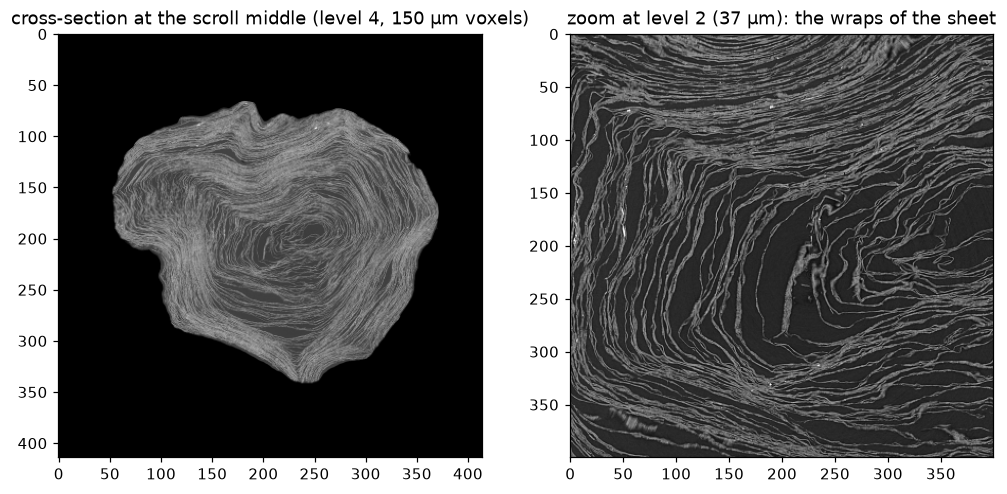

In [6]:
v4 = vlab.scroll_volume(4)
t = time.time(); sl = vlab.crop(v4, 'v4', v4.shape[0] // 2)
print(f'slice {sl.shape} in {time.time() - t:.1f}s (cached after the first run); value range {sl.min()}..{sl.max()}')
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(sl); ax[0].set_title('cross-section at the scroll middle (level 4, 150 µm voxels)')
v2 = vlab.scroll_volume(2); z2 = v2.shape[0] // 2
zoomed = vlab.crop(v2, 'v2mid', z2, slice(600, 1000), slice(600, 1000))
ax[1].imshow(zoomed); ax[1].set_title('zoom at level 2 (37 µm): the wraps of the sheet')
plt.show()

The bright spiral is papyrus; dark is air. In the zoom you can count wraps, and see where they touch or are crushed
together. Following **one** wrap through thousands of such slices, without jumping to its neighbour, is the
segmentation problem (notebook 02 uses a sheet someone already traced).

**How many wraps?** Walk outwards from the centre along a line and count the bright crossings. Each crossing is one
wrap (if the wraps are separated; crushed regions merge two into one, so the count is a lower bound).

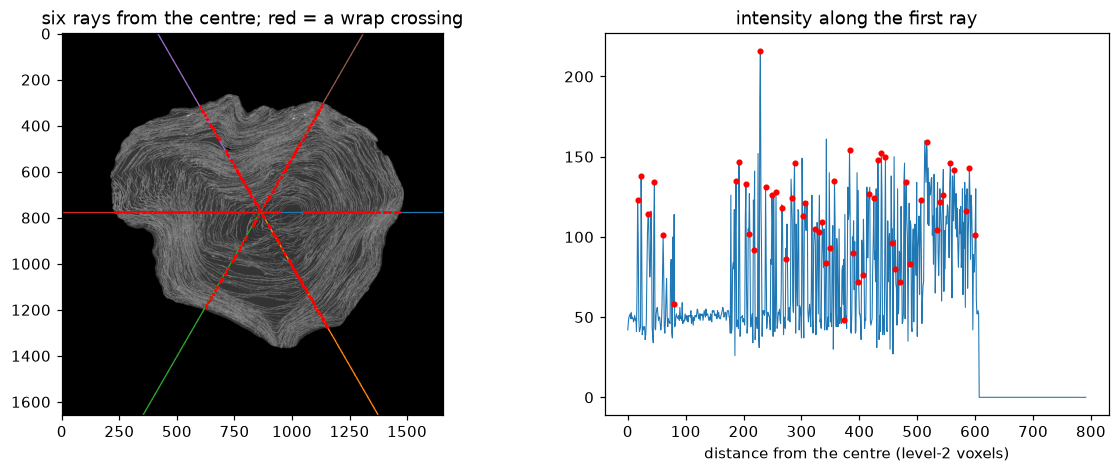

wrap crossings per ray: [52, 51, 30, 49, 46, 43] -> roughly 47 wraps visible at 37 µm (a lower bound)


In [7]:
from scipy.signal import find_peaks
v2s = vlab.crop(v2, 'v2full', z2).astype(np.float32)
mask = v2s > 0; cy, cx = [int(np.mean(i)) for i in np.nonzero(mask)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5)); ax[0].imshow(v2s)
counts = []
for ang in np.deg2rad([0, 60, 120, 180, 240, 300]):
    r = np.arange(0, 1200); yy, xx = (cy + r * np.sin(ang)).astype(int), (cx + r * np.cos(ang)).astype(int)
    ok = (yy >= 0) & (yy < v2s.shape[0]) & (xx >= 0) & (xx < v2s.shape[1]); yy, xx = yy[ok], xx[ok]
    prof = v2s[yy, xx]; inside = prof > 0
    pk, _ = find_peaks(np.convolve(prof, np.ones(3) / 3, 'same'), prominence=25, distance=4)
    pk = pk[inside[pk]]; counts.append(len(pk))
    ax[0].plot(xx, yy, lw=.8); ax[0].plot(xx[pk], yy[pk], 'r.', ms=2)
    if ang == 0: ax[1].plot(prof, lw=.7); ax[1].plot(pk, prof[pk], 'r.'); ax[1].set_xlabel('distance from the centre (level-2 voxels)')
ax[0].set_title('six rays from the centre; red = a wrap crossing'); ax[1].set_title('intensity along the first ray')
plt.show()
print('wrap crossings per ray:', counts, f'-> roughly {int(np.median(counts))} wraps visible at 37 µm (a lower bound)')

## 6. Along the scroll

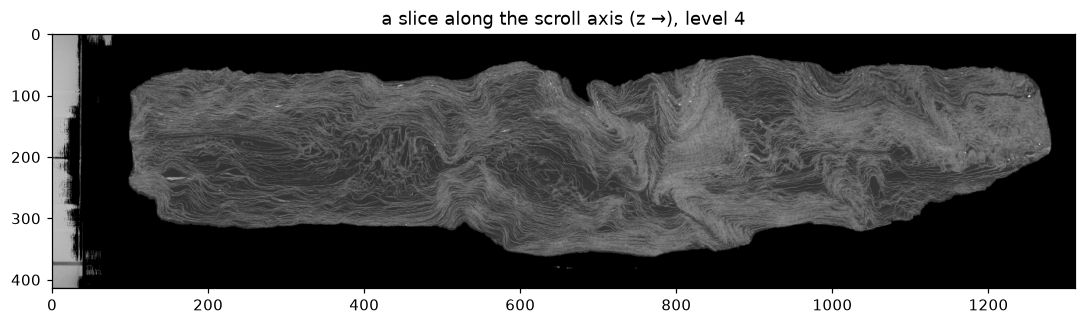

In [8]:
side = vlab.crop(v4, 'v4side', slice(None), v4.shape[1] // 2)
plt.figure(figsize=(12, 3)); plt.imshow(side.T, aspect='auto'); plt.title('a slice along the scroll axis (z →), level 4'); plt.show()

The scroll is not a neat cylinder: its cross-section changes along z, and the ends are damaged. Every stage above has
to cope with that.

## 7. What is still open (the 2026 open problems)

The challenge publishes its list of open problems (scrollprize.org/2026_open_problems). In short:

| # | problem | what a solution looks like |
|---|---|---|
| 1 | scan quality in compressed regions | better reconstruction (phase retrieval) or scan recipes where wraps are crushed |
| 2 | surface prediction and topology | papyrus masks without holes, merges or switches; topology-aware losses |
| 3 | mesh tracing and geometry | tracers that follow one sheet automatically over a whole scroll |
| 4 | label quality | snapping approximate human meshes to the real sheet; active learning |
| 5 | fibre tracing | papyrus fibres run in two directions and give the sheet's U and V axes |
| 6 | spiral fit and global priors | fit the whole scroll as one (deformed) spiral; winding numbers to detect switches |
| 7 | ink detection generalisation | models that work on scrolls they were not trained on |
| 8 | direct 3D ink segmentation | find ink in the 2.4 µm volume without flattening first |
| 9 | self-supervised 3D representations | pretrained 3D encoders (the challenge's "dinovol") for every downstream task |
| 10 | data infrastructure | streaming and processing terabyte volumes |

**Where a newcomer fits.** Besides the big prizes there are monthly progress prizes for released tools, models,
documentation and bug fixes. Code: github.com/ScrollPrize/villa. Models: huggingface.co/scrollprize. Community: the
Discord and scrollprize.substack.com.

## Check yourself

1. Why does the challenge use a pyramid instead of one big array?
2. Ink is carbon on carbon. Why does that make it harder than reading pencil on paper in an X-ray?
3. The En-Gedi scroll was read in 2015. What made it easier than a Herculaneum scroll?
4. In the zoomed cross-section, where would a tracer most likely jump from one wrap to the next?
5. Why is the wrap count from the rays a lower bound and not the true count?
6. A 2.4 µm scan shows more detail. Name two costs of using it instead of the 9.4 µm scan.